In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging

from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import matplotlib.pyplot as plt

from gt_concepts.shapley import exact_shapley_value, montecarlo_shapley_value
from gt_concepts.least_core import exact_least_core, montecarlo_least_core, ValuationResult
from gt_concepts.nucleolus import montecarlo_nucleolus, exact_nucleolus
from gt_concepts.banzhaf import exact_banzhaf_index, montecarlo_banzhaf_index
from gt_concepts.shapley_shubik import exact_shapley_shubik, montecarlo_shapley_shubik
from gt_concepts.gately_point import exact_gately_value, montecarlo_gately_value
from gt_concepts.deegan_packel import exact_deegan_packel_index, montecarlo_deegan_packel_index
from models.train_model import get_model
from utils.plotting import plot_single_valuation
from utils.evaluation import evaluate_model

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

In [49]:
DATASET_NAME = "yield_synthetic"
MODEL_NAME = "svm"
SCORING = "accuracy"
METHODS = ["shapley","least_core","nucleolus","banzhaf", "shapley_shubik","gately" ]
MONTE_CARLO = False
N_MC_ITERATIONS = 5000
RANDOM_STATE = 42

OUTPUT_DIR = Path(f"./output/feature_valuation/{DATASET_NAME}_{MODEL_NAME}_{SCORING}_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [50]:
def load_dataset(name: str):
    path_map = {
        "breast_cancer": "datasets/breast_cancer/breast_cancer_preprocessed.npz",
        "congress": "../datasets/congress/congress_preprocessed.npz",
        "wine": "../datasets/wine/wine_preprocessed.npz",
        "apple_quality": "../datasets/apple_quality/apple_quality_preprocessed_no_scaling.npz",
        "yield_synthetic": "../datasets/yield_synthetic/yield_preprocessed.npz"
    }
    path = Path(path_map[name])
    data = np.load(path, allow_pickle=True)
    feature_names = data["feature_names"].tolist() if "feature_names" in data else [f"f{i}" for i in range(data["X_train"].shape[1])]
    return data["X_train"], data["X_test"], data["y_train"], data["y_test"], feature_names

In [51]:
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)

class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer, feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score
        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score

In [52]:
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

In [53]:
X_train, X_test, y_train, y_test, feature_names = load_dataset(DATASET_NAME)
scorer = get_scorer(SCORING)
utility = Utility(
    X_train, y_train, X_test, y_test,
    MODEL_NAME,
    scorer,
    feature_names=feature_names,
    random_state=RANDOM_STATE
)

n_features = X_train.shape[1]
full_model_accuracy = utility(list(range(n_features)))
SHAPLEY_SHUBIK_THRESHOLD = full_model_accuracy / (1* n_features)

In [54]:
SHAPLEY_SHUBIK_THRESHOLD

0.21625

In [55]:
results = {}
use_exact = not MONTE_CARLO and X_train.shape[1] <= 15
if "shapley" in METHODS:
    val = exact_shapley_value(utility) if use_exact else montecarlo_shapley_value(utility, N_MC_ITERATIONS)
    results["shapley"] = val.values
if "least_core" in METHODS:
    val = exact_least_core(utility) if use_exact else montecarlo_least_core(utility, N_MC_ITERATIONS)
    results["least_core"] = val.values
if "nucleolus" in METHODS:
    val = exact_nucleolus(utility, N_MC_ITERATIONS) if use_exact else montecarlo_nucleolus(utility, N_MC_ITERATIONS)
    results["nucleolus"] = val.values if val is not None else None
if "banzhaf" in METHODS:
    val = exact_banzhaf_index(utility) if use_exact else montecarlo_banzhaf_index(utility, N_MC_ITERATIONS, normalized=True)
    results["banzhaf"] = val.values
if "shapley_shubik" in METHODS:
    val = exact_shapley_shubik(utility, SHAPLEY_SHUBIK_THRESHOLD) if use_exact else montecarlo_shapley_shubik(utility, N_MC_ITERATIONS)
    results["shapley_shubik"] = val.values
if "gately" in METHODS:
    val = exact_gately_value(utility) if use_exact else montecarlo_gately_value(utility, N_MC_ITERATIONS)
    results["gately"] = val.values
if "deegan_packel" in METHODS:
    baseline = utility([])
    full_model_accuracy = utility(range(X_train.shape[1]))
    threshhold = full_model_accuracy
    val = exact_deegan_packel_index(utility, threshhold,normalized=True) if use_exact else montecarlo_deegan_packel_index(utility, N_MC_ITERATIONS, normalized=True)
    results["deegan_packel"] = val.values
df = pd.DataFrame([
    {"method": m, "feature": feature_names[i], "value": v}
    for m, vals in results.items() for i, v in enumerate(vals)
])
df.head()

0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
0.32
['N

,method,feature,value
0,shapley,Nitrogen,0.077083
1,shapley,Irrigation,0.352083
2,shapley,Precipitation,0.093750
3,shapley,Herbicide,0.022083
4,least_core,Nitrogen,0.166250


In [56]:
df.to_csv(OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_feature_valuations.csv", index=False)

In [57]:
model_accurcy = utility(range(X_train.shape[1]))
print(f"Model accuracy with all features: {model_accurcy:.4f}")

Model accuracy with all features: 0.8650


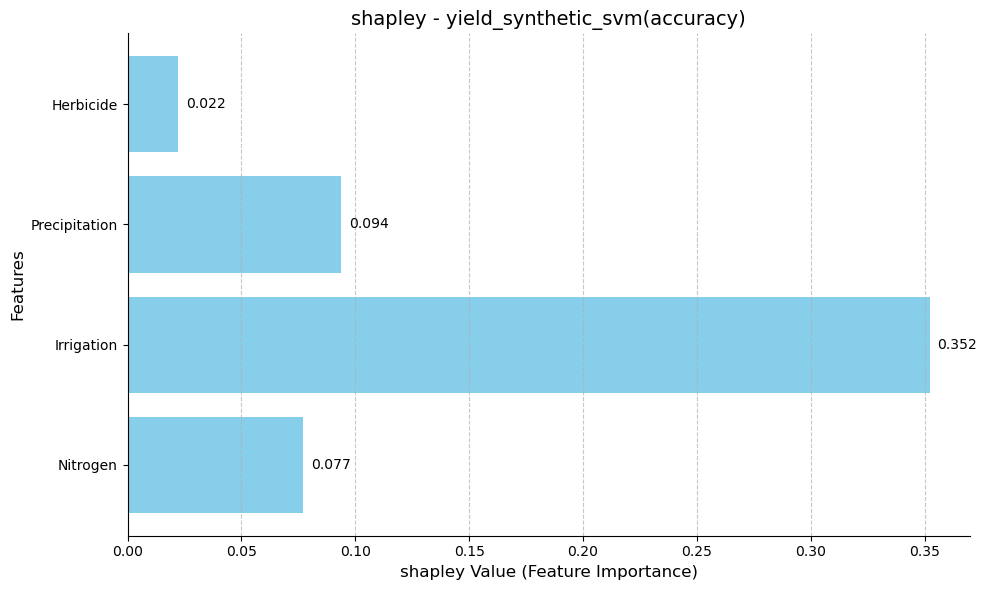

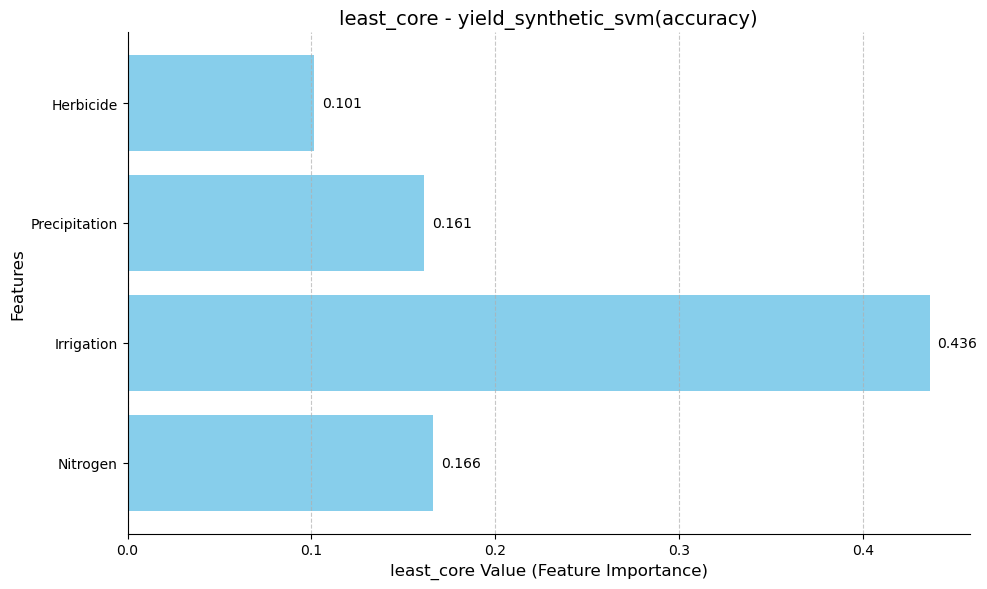

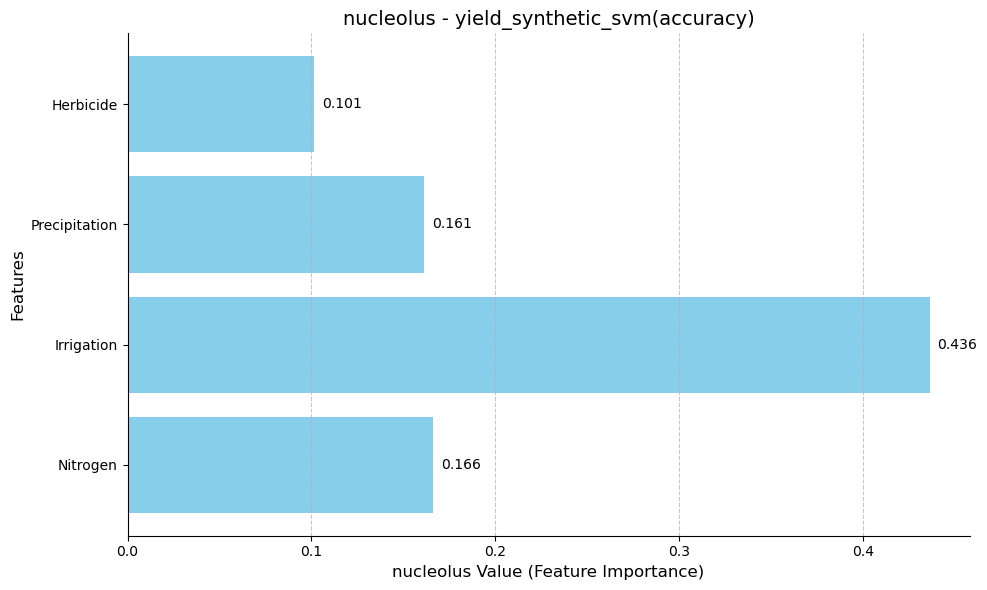

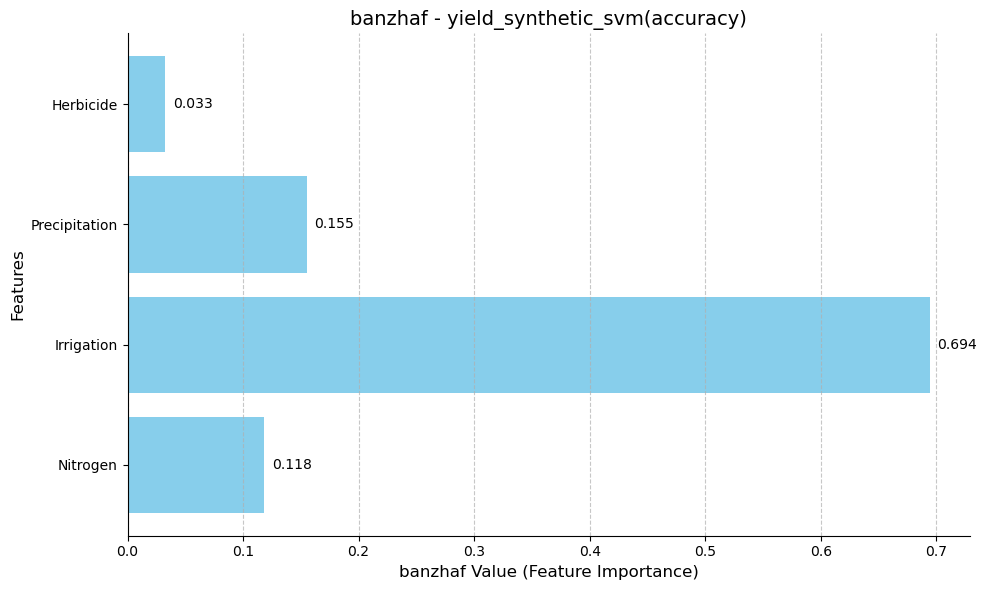

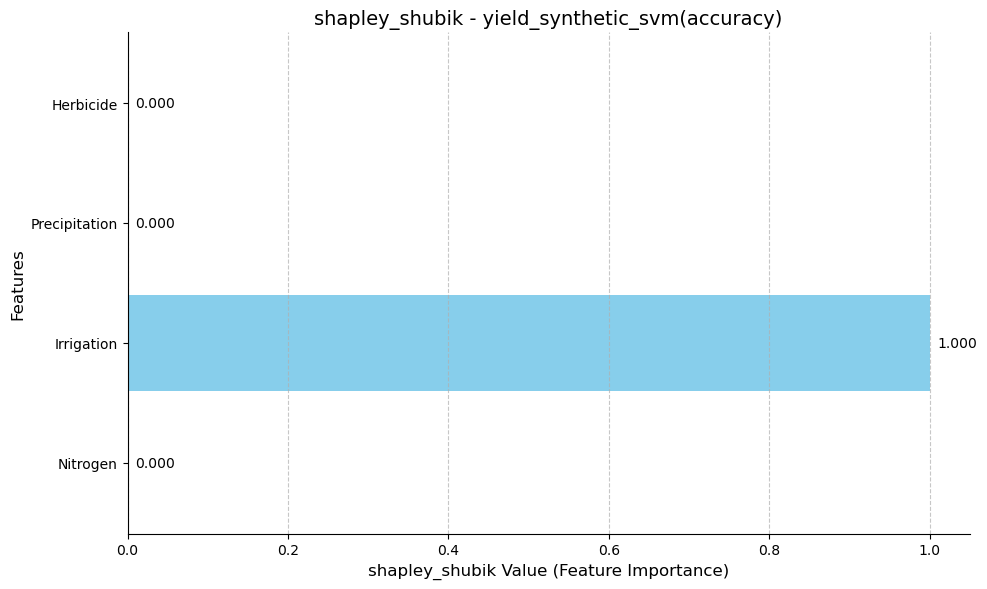

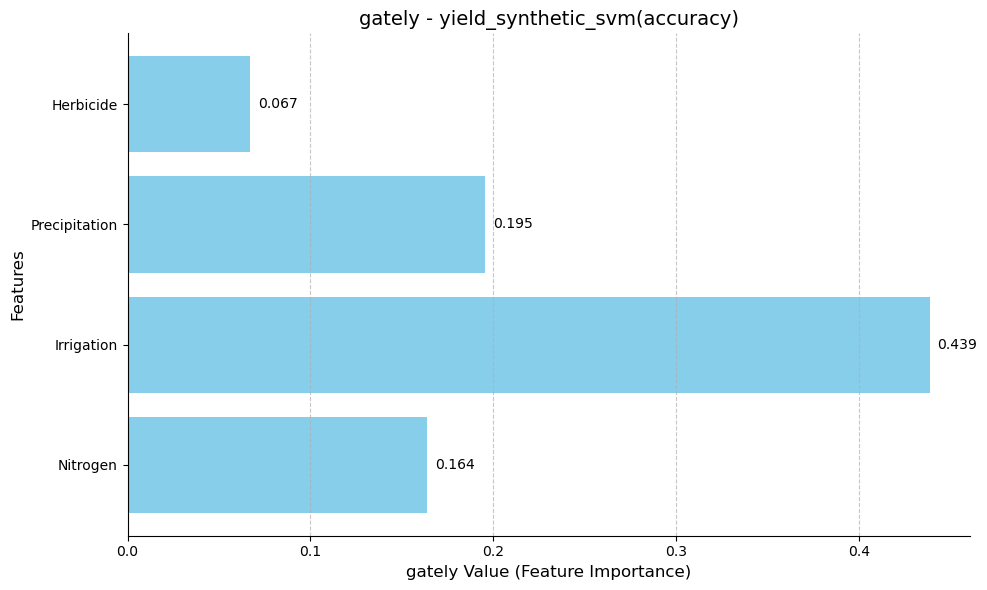

In [58]:
for method, vals in results.items():
    plot_single_valuation(
        vals, feature_names,
        method_name=method,
        title=f"{method} - {DATASET_NAME}_{MODEL_NAME}({SCORING})",
        output_path=OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_{method}_{SCORING}.png"
    )

In [59]:
from scipy.stats import spearmanr

methods = df["method"].unique()
rank_corr = pd.DataFrame(index=methods, columns=methods)
rankings = {m: df[df["method"] == m].sort_values("value", ascending=False)["feature"].tolist() for m in methods}

for m1 in methods:
    for m2 in methods:
        if m1 == m2:
            rank_corr.loc[m1, m2] = 1.0
        else:
            common = set(rankings[m1]) & set(rankings[m2])
            r1 = [rankings[m1].index(f) for f in common]
            r2 = [rankings[m2].index(f) for f in common]
            corr, _ = spearmanr(r1, r2)
            rank_corr.loc[m1, m2] = corr

rank_corr

,shapley,least_core,nucleolus,banzhaf,shapley_shubik,gately
shapley,1.0,0.8,0.8,1.0,0.8,1.0
least_core,0.8,1.0,1.0,0.8,1.0,0.8
nucleolus,0.8,1.0,1.0,0.8,1.0,0.8
banzhaf,1.0,0.8,0.8,1.0,0.8,1.0
shapley_shubik,0.8,1.0,1.0,0.8,1.0,0.8
gately,1.0,0.8,0.8,1.0,0.8,1.0


In [60]:
ground_truth = pd.Series({
    "Nitrogen": 2.764945,
    "Irrigation": 3.706509,
    "Precipitation": 2.052278,
    "Herbicide": 0.817947
}, name="GroundTruth")

gt_norm = ground_truth / ground_truth.sum()

In [61]:
df_val = df.copy()


Comparison with Ground Truth
           method  Spearman   Pearson  CosineSim      MAPE
5          gately  0.800000  0.892040   0.966479  0.195279
1      least_core  1.000000  0.860508   0.963813  0.277510
2       nucleolus  1.000000  0.860508   0.963813  0.277510
0         shapley  0.800000  0.848230   0.904112  0.476142
3         banzhaf  0.800000  0.828533   0.877327  0.567935
4  shapley_shubik  0.774597  0.750738   0.723243  1.130086


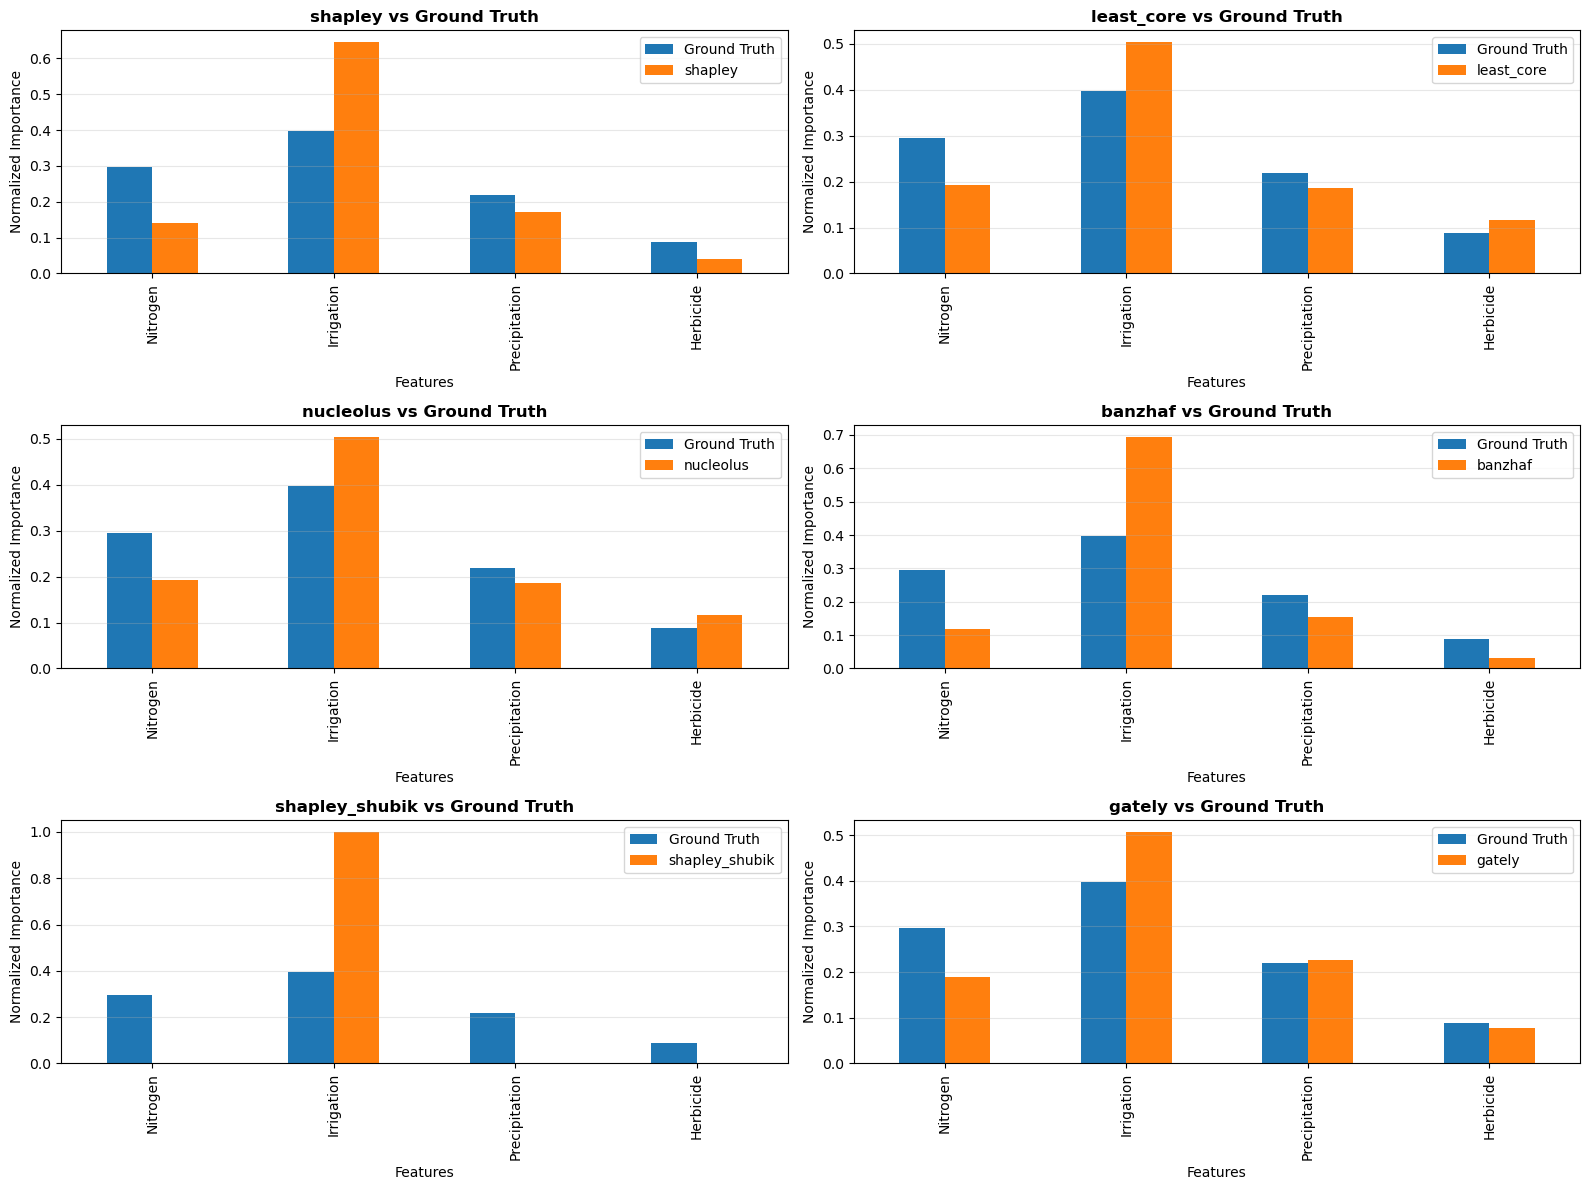


Comparison plot saved to: output/feature_valuation/yield_synthetic_svm_accuracy_results/yield_synthetic_svm_ground_truth_comparison.png


In [62]:
results = []

for method in df_val["method"].unique():
    subset = df_val[df_val["method"] == method].set_index("feature")["value"]

    subset_norm = subset / subset.sum()

    subset_norm = subset_norm[gt_norm.index]

    spearman_corr, _ = spearmanr(gt_norm, subset_norm)
    pearson_corr, _ = pearsonr(gt_norm, subset_norm)
    cos_sim = np.dot(gt_norm, subset_norm) / (norm(gt_norm) * norm(subset_norm))
    mape = (abs(gt_norm - subset_norm) / gt_norm).mean()

    results.append({
        "method": method,
        "Spearman": spearman_corr,
        "Pearson": pearson_corr,
        "CosineSim": cos_sim,
        "MAPE": mape
    })


results_df = pd.DataFrame(results).sort_values("CosineSim", ascending=False)
print("\nComparison with Ground Truth")
print(results_df)


methods_to_plot = df_val["method"].unique()
n_methods = len(methods_to_plot)

# Create 2-column layout: (rows=3, cols=2)
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()  # Flatten to 1D array for easy indexing

for idx, method in enumerate(methods_to_plot):
    ax = axes[idx]

    subset = df_val[df_val["method"] == method].set_index("feature")["value"]
    subset_norm = subset / subset.sum()
    subset_norm = subset_norm[gt_norm.index]

    pd.DataFrame({
        "Ground Truth": gt_norm,
        method: subset_norm
    }).plot(kind='bar', ax=ax)

    ax.set_title(f"{method} vs Ground Truth", fontsize=12, fontweight='bold')
    ax.set_ylabel("Normalized Importance")
    ax.set_xlabel("Features")
    ax.legend(loc='best')
    ax.grid(axis='y', alpha=0.3)

for idx in range(n_methods, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_ground_truth_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"\nComparison plot saved to: {OUTPUT_DIR / f'{DATASET_NAME}_{MODEL_NAME}_ground_truth_comparison.png'}")